# Building Cross Sectional Systematic Strategies by Learning to Rank

PI2 Project A5, in partnership with HSBC AM (Philippe DECLERCK)

**Team:** Edoardo VONA, Alvaro SERERO, Mehdi HASSAN (team referent), Maxence, Pierre, Sinthia VANELLE

**Data source:** `data.xlsx` Excel spreadsheet extracted from Bloomberg.

## Setup

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Step 1: Load the Bloomberg data

In [18]:
# Read the Excel file. The notebook is in notebooks/, the file is one folder up.
prices = pd.read_excel(
    "../data.xlsx",
    header=8,                 # row 9 in Excel holds the tickers
    index_col=0,              # first column = dates, used as the row index
    na_values=["#N/A N/A"],   # Bloomberg's "no data" marker becomes NaN
)
prices.index.name = "date"
prices.shape

(7007, 88)

In [19]:
prices

,XM1 Comdty,CN1 Comdty,RX1 Comdty,G 1 Comdty,JB1 Comdty,UXY1 Comdty,KAA1 Comdty,OAT1 Comdty,IK1 Comdty,BO1 Comdty,...,CZKUSDCR Curncy,HUFUSDCR Curncy,IDRUSDCR Curncy,INRUSDCR Curncy,KRWUSDCR Curncy,MXNUSDCR Curncy,PLNUSDCR Curncy,SGDUSDCR Curncy,TWDUSDCR Curncy,ZARUSDCR Curncy
date,,,,,,,,,,,,,,,,,,,,,
2000-01-03,90.7054,64.95,65.67,55.28,92.90,NaN,NaN,NaN,NaN,19.08,...,86.9349,94.7530,135.5737,104.8794,108.1441,125.9173,92.9915,96.6450,104.2097,103.8351
2000-01-04,90.5492,64.41,65.57,54.53,92.36,NaN,NaN,NaN,NaN,19.24,...,86.7332,96.1954,133.9730,104.9538,108.6470,125.1059,93.0895,96.6318,106.9662,104.5632
2000-01-05,90.6663,63.90,65.40,54.18,92.64,NaN,NaN,NaN,NaN,19.45,...,87.0944,96.3343,133.6163,105.0049,107.4731,125.1710,93.0859,96.5425,106.2992,104.9559
2000-01-06,90.5688,64.18,65.31,54.12,92.78,NaN,NaN,NaN,NaN,19.43,...,87.1095,96.3733,132.1587,104.9000,106.3709,125.1157,94.1179,96.1119,105.9962,104.7967
2000-01-07,90.5883,64.38,65.84,54.37,92.47,NaN,NaN,NaN,NaN,19.65,...,87.2739,96.0965,133.2854,104.8932,107.1878,125.3724,94.2959,96.2838,105.9922,105.1856
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-04,94.9100,117.79,122.72,86.68,126.40,108.437500,108.50,109.63,112.96,63.53,...,143.0143,186.7871,234.1702,176.4701,98.8440,249.1690,204.8732,98.7779,76.9986,158.6667
2026-11-05,94.9850,118.08,123.16,86.82,127.04,108.953125,109.19,109.81,113.13,62.24,...,142.5412,185.6563,235.2646,176.8219,97.7537,247.3687,204.0671,98.8305,76.8574,158.0579
2026-11-06,95.0100,118.29,123.12,86.74,128.21,108.734375,109.37,110.03,113.23,62.26,...,141.5669,185.0033,234.9069,177.9000,97.1799,249.2561,202.9680,98.4512,77.0956,157.5442


In [20]:
prices.columns

Index(['XM1 Comdty', 'CN1 Comdty', 'RX1 Comdty', 'G 1 Comdty', 'JB1 Comdty',
       'UXY1 Comdty', 'KAA1 Comdty', 'OAT1 Comdty', 'IK1 Comdty', 'BO1 Comdty',
       'CL1 Comdty', 'CO1 Comdty', 'C 1 Comdty', 'CT1 Comdty', 'GC1 Comdty',
       'HG1 Comdty', 'HO1 Comdty', 'KC1 Comdty', 'KW1 Comdty', 'LA1 Comdty',
       'LC1 Comdty', 'LH1 Comdty', 'LL1 Comdty', 'LN1 Comdty', 'LX1 Comdty',
       'NG1 Comdty', 'QS1 Comdty', 'SB1 Comdty', 'SI1 Comdty', 'SM1 Comdty',
       'S 1 Comdty', 'W 1 Comdty', 'XB1 Comdty', 'CC1 Comdty', 'XP1 Index',
       'PT1 Index', 'SM1 Index', 'GX1 Index', 'IB1 Index', 'CF1 Index',
       'Z 1 Index', 'ST1 Index', 'QC1 Index', 'TP1 Index', 'VG1 Index',
       'NQ1 Index', 'ES1 Index', 'HI1 Index', 'NI1 Index', 'DM1 Index',
       'RTY1 Index', 'FA1 Index', 'BZ1 Index', 'IF1 Index', 'HHI1 Index',
       'IN1 Index', 'KM1 Index', 'TW1 Index', 'MX1 Index', 'MES1 Index',
       'BZ1 Index.1', 'IN1 Index.1', 'TW1 Index.1', 'HHI1 Index.1',
       'MX1 Index.1', 'AUDUS

In [21]:
# Drop the duplicated columns (pandas renamed them "XXX.1")
prices = prices.loc[:, ~prices.columns.str.endswith(".1")]

# Drop columns with no data at all (HHI1 Index)
prices = prices.dropna(axis=1, how="all")

# Emerging-market extras: some are frozen or suspicious, set aside until checked
EM_EXTRAS = ["BZ1 Index", "IF1 Index", "IN1 Index", "KM1 Index",
             "TW1 Index", "MX1 Index", "MES1 Index"]
prices = prices.drop(columns=EM_EXTRAS)

# KAA1 has zero / frozen prices before 25/10/2010: treat it as starting then
prices.loc[:"2010-10-22", "KAA1 Comdty"] = np.nan

# The yuan was pegged to the dollar until 21/07/2005: no real market before that
prices.loc[:"2005-07-21", "CNYUSDCR Curncy"] = np.nan

prices.shape

(7007, 75)

We get a clean DataFrame of 7007 rows by 75 columns:
- **7007 rows:** every weekday from January 2000 to 10 November 2026.
- **75 columns:** the Bloomberg tickers of assets from 4 classes: bonds, commodities, equities, FX.

## Step 2: Tag each asset with its class, and see how the universe grows

In [22]:
BONDS = ["XM1 Comdty", "CN1 Comdty", "RX1 Comdty", "G 1 Comdty", "JB1 Comdty",
         "UXY1 Comdty", "KAA1 Comdty", "OAT1 Comdty", "IK1 Comdty"]

# One label per column, same order as prices.columns
asset_class = pd.Series("Commodities", index=prices.columns)
asset_class[BONDS] = "Bonds"
asset_class[prices.columns.str.endswith("Curncy")] = "FX"
asset_class[prices.columns.str.endswith("Index")] = "Equities"

asset_class.value_counts()

Commodities    25
FX             23
Equities       18
Bonds           9
Name: count, dtype: int64

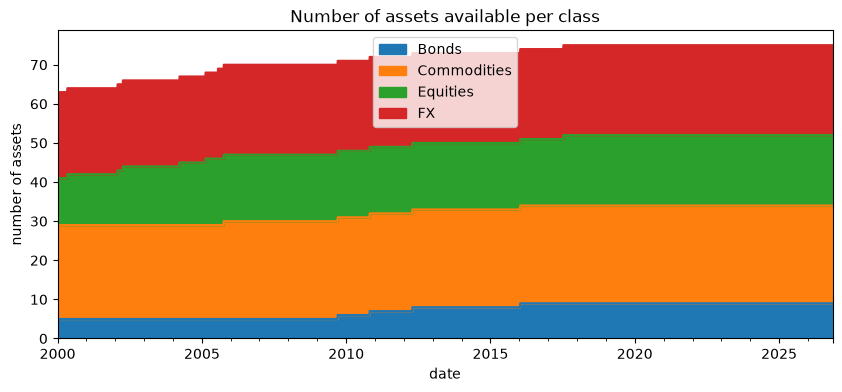

In [23]:
# True where a price exists, then count per class for each day
counts = prices.notna().T.groupby(asset_class).sum().T

counts.plot.area(figsize=(10, 4), title="Number of assets available per class")
plt.ylabel("number of assets")
plt.show()

## Step 3: Clean the bad series, then compute daily returns

### Daily returns
- We use the pandas function `pct_change` to get the returns from one row to another (daily returns).
- `fill_method=None` is used as argument so that missing prices aren't filled before computing returns: with it, a missing price gives a missing return instead of inventing data.

In [24]:
# Return on day t = price_t / price_(t-1) - 1
returns = prices.pct_change(fill_method=None)
returns.tail()

,XM1 Comdty,CN1 Comdty,RX1 Comdty,G 1 Comdty,JB1 Comdty,UXY1 Comdty,KAA1 Comdty,OAT1 Comdty,IK1 Comdty,BO1 Comdty,...,CZKUSDCR Curncy,HUFUSDCR Curncy,IDRUSDCR Curncy,INRUSDCR Curncy,KRWUSDCR Curncy,MXNUSDCR Curncy,PLNUSDCR Curncy,SGDUSDCR Curncy,TWDUSDCR Curncy,ZARUSDCR Curncy
date,,,,,,,,,,,,,,,,,,,,,
2026-11-04,0.000053,0.004777,0.001632,0.008963,-0.002447,0.004487,0.003607,0.009484,0.006236,-0.026808,...,0.006021,0.009690,-0.000848,0.001227,0.003214,0.011586,0.009449,0.002415,-0.001437,0.012311
2026-11-05,0.000790,0.002462,0.003585,0.001615,0.005063,0.004755,0.006359,0.001642,0.001505,-0.020305,...,-0.003308,-0.006054,0.004674,0.001994,-0.011031,-0.007225,-0.003935,0.000533,-0.001834,-0.003837
2026-11-06,0.000263,0.001778,-0.000325,-0.000921,0.009210,-0.002008,0.001649,0.002003,0.000884,0.000321,...,-0.006835,-0.003517,-0.001520,0.006097,-0.005870,0.007630,-0.005386,-0.003838,0.003099,-0.003250
2026-11-09,-0.000211,0.001184,-0.001706,0.001845,-0.002730,-0.000144,0.000183,0.001454,0.001148,-0.003694,...,0.007244,0.010026,0.001520,-0.000033,0.016476,0.004415,0.008669,0.002800,-0.003960,0.009756
2026-11-10,0.000158,-0.003715,-0.000244,-0.004143,-0.001408,-0.008336,0.000823,0.000635,0.000441,-0.004836,...,-0.004356,-0.007964,0.001963,0.000000,-0.000935,-0.008279,-0.004851,-0.002055,-0.000030,-0.006499


### Sanity check, the 5 biggest daily moves

In [25]:
returns.abs().stack().sort_values(ascending=False).head(5)

date                  
2022-03-07  LN1 Comdty    0.634603
2020-04-21  CL1 Comdty    0.433414
2003-02-24  NG1 Comdty    0.383137
2020-03-23  XB1 Comdty    0.319945
2026-01-30  SI1 Comdty    0.313720
dtype: float64

We get real events:
- **Nickel (LN1), +63% on 7 March 2022:** the famous nickel short squeeze on the London Metal Exchange.
- **WTI oil (CL1), −43% on 21 April 2020:** oil prices collapsed during COVID.
- **Natural gas (NG1) 2003, gasoline (XB1) March 2020, silver (SI1) January 2026.**

### Annual volatility per asset class

- `returns.std()` is the standard deviation of daily returns which gives us the daily volatility.
- then we annualise the daily volatility with a square root of time to get the annual volatility: daily vol × √252 (252 trading days per year). We use the square root because the variances of independent returns add up over time.

In [26]:
vol = returns.std() * np.sqrt(252)      # daily std -> yearly
vol.groupby(asset_class).median()

Bonds          0.058472
Commodities    0.288140
Equities       0.215876
FX             0.111774
dtype: float64

**Medians:** bonds about 6%, FX about 11%, equities about 22%, commodities about 29%.

## Step 4: Volatility scaling

**The problem (seen at step 3):** natural gas moves about 50 times more than the Australian bond. If we put the same amount of money on each, the portfolio’s results would really just be the natural gas results.

**The paper’s fix (Poh et al.):** size each position so that every asset contributes the same risk. Each asset’s return is multiplied by: **target vol / the asset’s estimated vol**.

The paper uses a **target of 15% per year**. A calm asset gets a bigger position, a wild one a smaller one.

Two details that matter:

1. **How we estimate an asset’s vol.** The paper uses an exponentially weighted standard deviation over about 60 days. “Exponentially weighted” means recent days count more than old ones, so the estimate reacts quickly when markets get calmer or rougher.
2. **No peeking into the future.** On day t we decide the position using only data up to day t. That position then earns the return of day t+1. In code, that’s .shift(1): today’s return gets multiplied by yesterday’s vol estimate. If we forgot it, we’d be using information we couldn’t have had at the time. That’s called look-ahead bias, and it’s the classic way to fake a great backtest.

### Ex-ante volatility = volatility estimated using past data only

- `min_periods=60:` we don’t trust the estimate until we have 60 days of data, so the first 60 days stay empty.

In [27]:
# "Ex-ante" = estimated with past data only
ex_ante_vol = returns.ewm(span=60, min_periods=60).std() * np.sqrt(252)
ex_ante_vol.iloc[-1].sort_values()     # today's estimate for each asset

XM1 Comdty         0.007515
CNYUSDCR Curncy    0.014823
SGDUSDCR Curncy    0.030374
IDRUSDCR Curncy    0.042441
INRUSDCR Curncy    0.043193
                     ...   
NG1 Comdty         0.448106
HO1 Comdty         0.488342
CL1 Comdty         0.496792
CO1 Comdty         0.522949
QS1 Comdty         0.550242
Name: 2026-11-10 00:00:00, Length: 75, dtype: float64

### Scale the returns and check

In [28]:
TARGET_VOL = 0.15

# Yesterday's vol estimate sizes today's return (no look-ahead)
scaled_returns = returns * (TARGET_VOL / ex_ante_vol.shift(1))

realised = scaled_returns.std() * np.sqrt(252)
realised.sort_values()

XM1 Comdty         0.153246
SEKUSDCR Curncy    0.153255
CN1 Comdty         0.153261
EURUSDCR Curncy    0.153289
CADUSDCR Curncy    0.153298
                     ...   
LN1 Comdty         0.161287
TWDUSDCR Curncy    0.162375
INRUSDCR Curncy    0.162473
CHFUSDCR Curncy    0.172804
CNYUSDCR Curncy    0.176077
Length: 75, dtype: float64

- Almost every asset now lands at about 15.3–15.5%, from bonds to natural gas.
- **Except one:** CNYUSDCR (the Chinese yuan) comes out at about 70%. The reason is that China pegged the yuan to the dollar until July 2005. Its price barely moved, the estimated vol was about 0.08%, and so the formula put on a position about 500 times the normal size. Any tiny move then exploded.

We can conclude that **vol scaling breaks on an asset that doesn’t really trade freely**.

**The fix:** we handle it like KAA1, and start CNY when the peg ended. (see cell 2)